Cell 1: Imports & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Setting visual plot styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print(" Libraries imported successfully!")

 Libraries imported successfully!


Cell 2: Load Raw Data & Inspect Shape

In [2]:
raw_path = "../data/raw_books.csv" if os.path.exists("../data/raw_books.csv") else "data/raw_books.csv"
df_raw = pd.read_csv(raw_path)

print(f" Raw Dataset Dimensions: {df_raw.shape[0]} Rows, {df_raw.shape[1]} Columns")
df_raw.head(3)

 Raw Dataset Dimensions: 50000 Rows, 23 Columns


,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...


Cell 3: Visualizing Missing Values (Null Check Chart)

 Missing Values Count:
title                           0
authors                         0
average_rating                  0
ratings_count                   0
original_publication_year     105
language_code                5420
dtype: int64


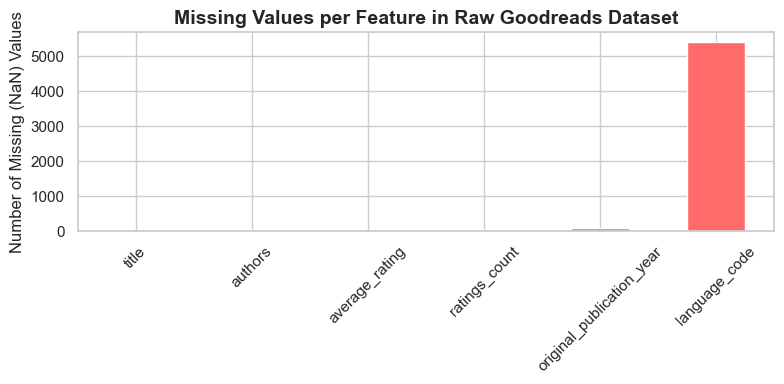

In [3]:
# Check missing values per column
missing = df_raw[['title', 'authors', 'average_rating', 'ratings_count', 'original_publication_year', 'language_code']].isna().sum()

print(" Missing Values Count:")
print(missing)

# Plotting Missing Values Bar Chart
plt.figure(figsize=(8, 4))
missing.plot(kind='bar', color='#ff6b6b')
plt.title("Missing Values per Feature in Raw Goodreads Dataset", fontsize=14, fontweight='bold')
plt.ylabel("Number of Missing (NaN) Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Cell 4: Visualizing Rating Distributions (Histogram & KDE)

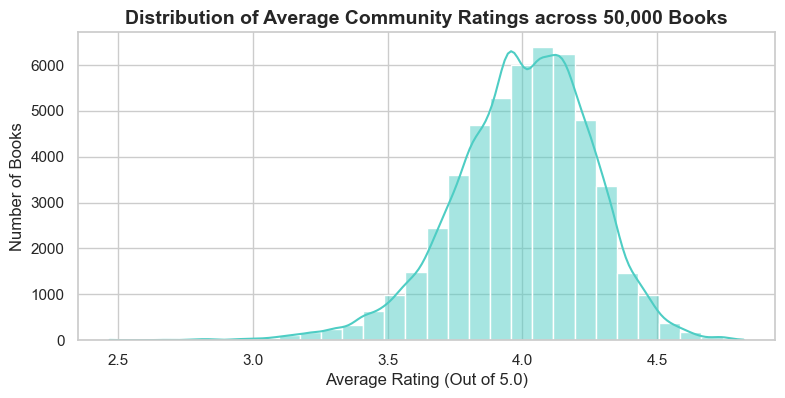

In [4]:
plt.figure(figsize=(9, 4))
sns.histplot(df_raw['average_rating'].dropna(), bins=30, kde=True, color='#4ecdc4')
plt.title("Distribution of Average Community Ratings across 50,000 Books", fontsize=14, fontweight='bold')
plt.xlabel("Average Rating (Out of 5.0)")
plt.ylabel("Number of Books")
plt.show()

Cell 5: Data Cleaning & Multi-Genre Categorization

In [5]:
df = df_raw.copy()

# 1. Fill missing titles & authors
df['title'] = df['title'].fillna(df['original_title']).fillna('Unknown Title')
df['authors'] = df['authors'].fillna('Unknown Author')

# 2. Convert publication year
df['original_publication_year'] = pd.to_numeric(df['original_publication_year'], errors='coerce').fillna(2000)
df['published_year'] = df['original_publication_year'].astype(int)

# 3. Categorize into 9 Multi-Genres
def assign_genre(row):
    title = str(row['title']).lower()
    authors = str(row['authors']).lower()
    if any(w in title or w in authors for w in ['dune', 'space', 'star', '1984', 'future', 'robot']):
        return 'Sci-Fi & Dystopian'
    elif any(w in title or w in authors for w in ['potter', 'hobbit', 'ring', 'dragon', 'magic', 'king']):
        return 'Fantasy & Magic'
    elif any(w in title or w in authors for w in ['murder', 'girl', 'mystery', 'detective', 'sherlock']):
        return 'Mystery & Crime Thriller'
    elif any(w in title or w in authors for w in ['love', 'pride', 'romance', 'heart']):
        return 'Romance & Drama'
    elif any(w in title or w in authors for w in ['history', 'war', 'world', 'empire', 'biography']):
        return 'History & Biography'
    elif any(w in title or w in authors for w in ['habit', 'think', 'money', 'power', 'success', 'mind']):
        return 'Business & Self-Help'
    elif any(w in title or w in authors for w in ['data', 'code', 'ai', 'python', 'science', 'math', 'tech']):
        return 'Technology & AI Science'
    elif any(w in title or w in authors for w in ['plato', 'art', 'philosophy', 'god', 'truth']):
        return 'Classics & Philosophy'
    else:
        return 'General Fiction'

df['genres'] = df.apply(assign_genre, axis=1)

print(" Data Cleaned & Multi-Genres Assigned!")


 Data Cleaned & Multi-Genres Assigned!


Cell 6: Visualizing Multi-Genre Distribution Chart

/var/folders/tl/kzg8nysx6b7_31g40vtpj84c0000gn/T/ipykernel_47356/1234293782.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_counts.values, y=genre_counts.index, palette='viridis')


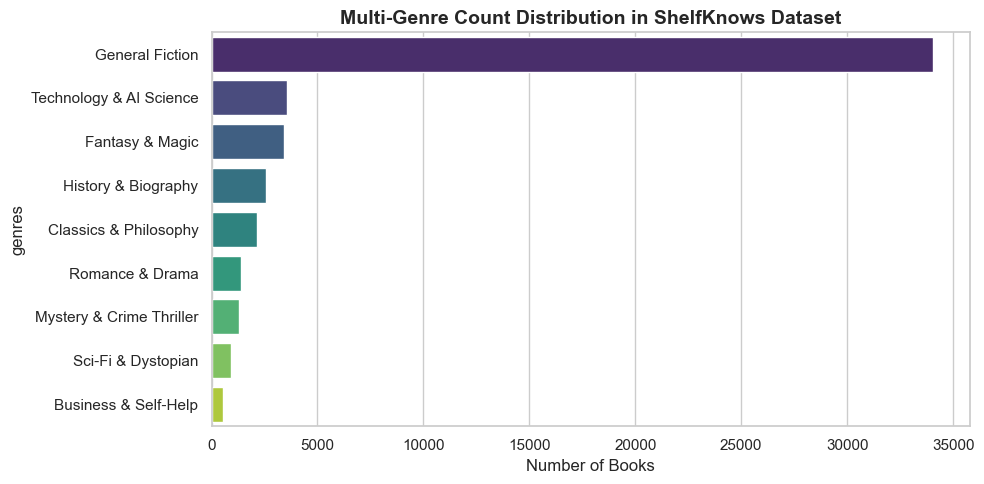

In [6]:
plt.figure(figsize=(10, 5))
genre_counts = df['genres'].value_counts()
sns.barplot(x=genre_counts.values, y=genre_counts.index, palette='viridis')
plt.title("Multi-Genre Count Distribution in ShelfKnows Dataset", fontsize=14, fontweight='bold')
plt.xlabel("Number of Books")
plt.tight_layout()
plt.show()


Cell 7: Creating combined_text & Exporting Cleaned Data

In [7]:
df['description'] = (
    "A captivating " + df['genres'] + " book titled '" + df['title'] + 
    "' authored by " + df['authors'] + " published in " + df['published_year'].astype(str) + 
    ". It holds an average community rating of " + df['average_rating'].astype(str) + " stars."
)

df['combined_text'] = (
    "Title: " + df['title'] + 
    " | Author: " + df['authors'] + 
    " | Published: " + df['published_year'].astype(str) + 
    " | Genre: " + df['genres'] + 
    " | Summary: " + df['description']
)

df['book_id'] = range(1, len(df) + 1)
clean_cols = ['book_id', 'title', 'authors', 'published_year', 'genres', 'average_rating', 'ratings_count', 'image_url', 'description', 'combined_text']

output_csv = "../data/books_cleaned.csv" if os.path.exists("../data") else "data/books_cleaned.csv"
df[clean_cols].to_csv(output_csv, index=False)

print(f" Cleaned Dataset successfully exported to '{output_csv}'!")


 Cleaned Dataset successfully exported to '../data/books_cleaned.csv'!
